<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1012/abalone_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [28]:
# 데이터 불러오기
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")

print(df.head())
print(df.shape)

   id Sex  Length  Diameter  Height  Whole_weight  Shucked_weight  \
0   0   M   0.455     0.365   0.095        0.5140          0.2245   
1   1   M   0.350     0.265   0.090        0.2255          0.0995   
2   2   F   0.530     0.420   0.135        0.6770          0.2565   
3   3   M   0.440     0.365   0.125        0.5160          0.2155   
4   4   I   0.330     0.255   0.080        0.2050          0.0895   

   Viscera_weight  Shell_weight  Rings  
0          0.1010         0.150     15  
1          0.0485         0.070      7  
2          0.1415         0.210      9  
3          0.1140         0.155     10  
4          0.0395         0.055      7  
(4177, 10)


In [29]:
# Rings 값의 분포 확인
print("\nRings value counts:")
print(df["Rings"].value_counts().sort_index())

# 입력 / 정답 분리
X = df.drop(["id", "Sex", "Rings"], axis=1)
y = df["Rings"]

# Rings 원-핫 인코딩
encoder = OneHotEncoder(sparse_output=False, dtype=int)
y_onehot = encoder.fit_transform(y.to_numpy().reshape(-1, 1))
print("\n원-핫 인코딩 결과:")
print(y_onehot[:5])
print("원-핫 인코딩 형태:", y_onehot.shape)

# 데이터 분리 및 표준화
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Rings value counts:
Rings
1       1
2       1
3      15
4      57
5     115
6     259
7     391
8     568
9     689
10    634
11    487
12    267
13    203
14    126
15    103
16     67
17     58
18     42
19     32
20     26
21     14
22      6
23      9
24      2
25      1
26      1
27      2
29      1
Name: count, dtype: int64

원-핫 인코딩 결과:
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
원-핫 인코딩 형태: (4177, 28)


In [30]:
# KNN
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)
knn_score = accuracy_score(y_test, knn_pred)
print("KNN:", knn_score)

KNN: 0.2117224880382775


In [31]:
# Logistic Regression
logistic = LogisticRegression(max_iter=2000)
logistic.fit(X_train_scaled, y_train)

logistic_pred = logistic.predict(X_test_scaled)
logistic_score = accuracy_score(y_test, logistic_pred)
print("Logistic Regression:", logistic_score)

Logistic Regression: 0.26555023923444976


In [32]:
# Decision Tree
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_score = accuracy_score(y_test, tree_pred)
print("Decision Tree:", tree_score)

Decision Tree: 0.2021531100478469


In [33]:
# Random Forest
forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
forest.fit(X_train, y_train)

forest_pred = forest.predict(X_test)
forest_score = accuracy_score(y_test, forest_pred)
print("Random Forest:", forest_score)

Random Forest: 0.23923444976076555


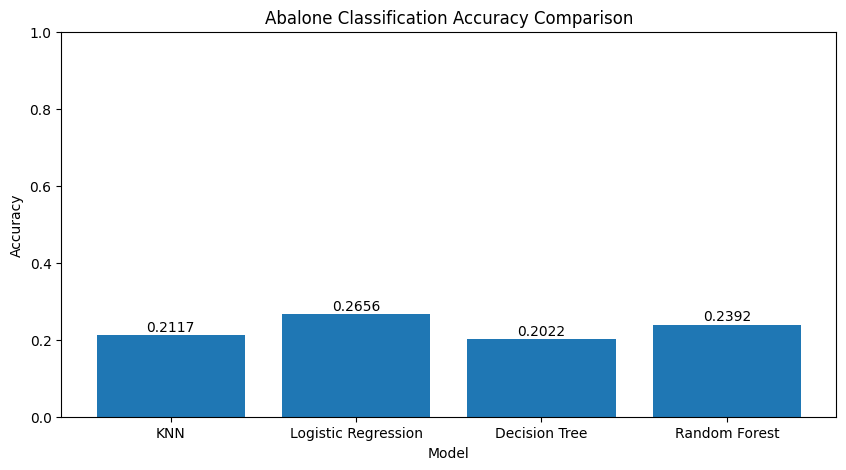

In [34]:
# 모델별 정확도 비교 시각화
model_names = [
    "KNN",
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

model_scores = [
    knn_score,
    logistic_score,
    tree_score,
    forest_score
]

plt.figure(figsize=(10, 5))
plt.bar(model_names, model_scores)

plt.title("Abalone Classification Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, score in enumerate(model_scores):
    plt.text(
        i, score + 0.01,
        f"{score:.4f}",
        ha="center"
    )

plt.show()


In [35]:
# 분류 결과 상세 평가 (Random Forest)
print("\nClassification Report (Random Forest):")
print(classification_report(
    y_test,
    forest_pred,
    zero_division=0
))


Classification Report (Random Forest):
              precision    recall  f1-score   support

           3       0.40      0.67      0.50         3
           4       0.26      0.38      0.31        13
           5       0.46      0.38      0.41        32
           6       0.33      0.35      0.34        48
           7       0.27      0.25      0.26        84
           8       0.27      0.36      0.31        99
           9       0.24      0.27      0.25       142
          10       0.22      0.24      0.23       139
          11       0.23      0.26      0.24        93
          12       0.17      0.14      0.15        51
          13       0.03      0.03      0.03        31
          14       0.18      0.08      0.11        26
          15       0.00      0.00      0.00        21
          16       0.20      0.08      0.11        13
          17       0.17      0.12      0.14         8
          18       0.00      0.00      0.00        12
          19       0.00      0.00      0.